In [7]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
df=pd.read_csv("../data/StudentsPerformance.csv")
df.head()


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [10]:
print(df.shape)
df.dtypes

(1000, 8)


gender                           str
race/ethnicity                   str
parental level of education      str
lunch                            str
test preparation course          str
math score                     int64
reading score                  int64
writing score                  int64
dtype: object

In [8]:
print(round(df.describe(),2))

       math score  reading score  writing score
count     1000.00        1000.00        1000.00
mean        66.09          69.17          68.05
std         15.16          14.60          15.20
min          0.00          17.00          10.00
25%         57.00          59.00          57.75
50%         66.00          70.00          69.00
75%         77.00          79.00          79.00
max        100.00         100.00         100.00


In [10]:
print(df.isnull().sum())
print(df.isna().sum())
print(df.duplicated().sum())

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64
0


In [12]:
print(df[~df["math score"].between(0,100)])
print(df[~df["reading score"].between(0,100)])
print(df[~df["writing score"].between(0,100)])

Empty DataFrame
Columns: [gender, race/ethnicity, parental level of education, lunch, test preparation course, math score, reading score, writing score]
Index: []
Empty DataFrame
Columns: [gender, race/ethnicity, parental level of education, lunch, test preparation course, math score, reading score, writing score]
Index: []
Empty DataFrame
Columns: [gender, race/ethnicity, parental level of education, lunch, test preparation course, math score, reading score, writing score]
Index: []


In [20]:
df.groupby("race/ethnicity").agg({
    "math score":"mean",
    "reading score":"mean",
    "writing score":"mean",}
)


,math score,reading score,writing score
race/ethnicity,,,
group A,61.629213,64.674157,62.674157
group B,63.452632,67.352632,65.600000
group C,64.463950,69.103448,67.827586
group D,67.362595,70.030534,70.145038
group E,73.821429,73.028571,71.407143


The groupe E has higher mean than the other groupes in evry subjects

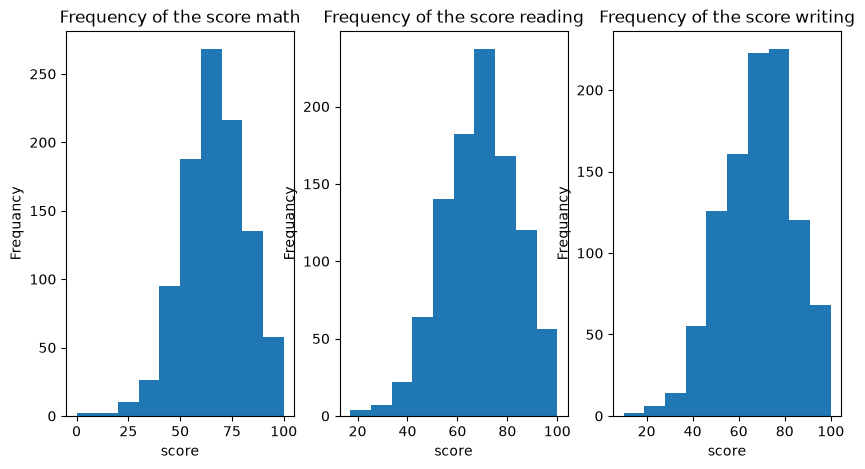

In [32]:
plt.figure(figsize=(10, 5))
plt.subplot(1,3,1)
plt.hist(df["math score"])
plt.title("Frequency of the score math")
plt.xlabel("score")
plt.ylabel("Frequancy")
plt.subplot(1,3,2)
plt.hist(df["reading score"])
plt.title("Frequency of the score reading")
plt.xlabel("score")
plt.ylabel("Frequancy")
plt.subplot(1,3,3)
plt.hist(df["writing score"])
plt.title("Frequency of the score writing")
plt.xlabel("score")
plt.ylabel("Frequancy")
plt.savefig("../graphes/graphe1",dpi=300)
plt.show()


In [43]:
print(df.groupby("lunch").agg({
    "math score":"mean",
    "reading score":"mean",
    "writing score":"mean",}
))
df["gender"].value_counts(normalize=True)*100

              math score  reading score  writing score
lunch                                                 
free/reduced   58.921127      64.653521      63.022535
standard       70.034109      71.654264      70.823256


gender
female    51.8
male      48.2
Name: proportion, dtype: float64

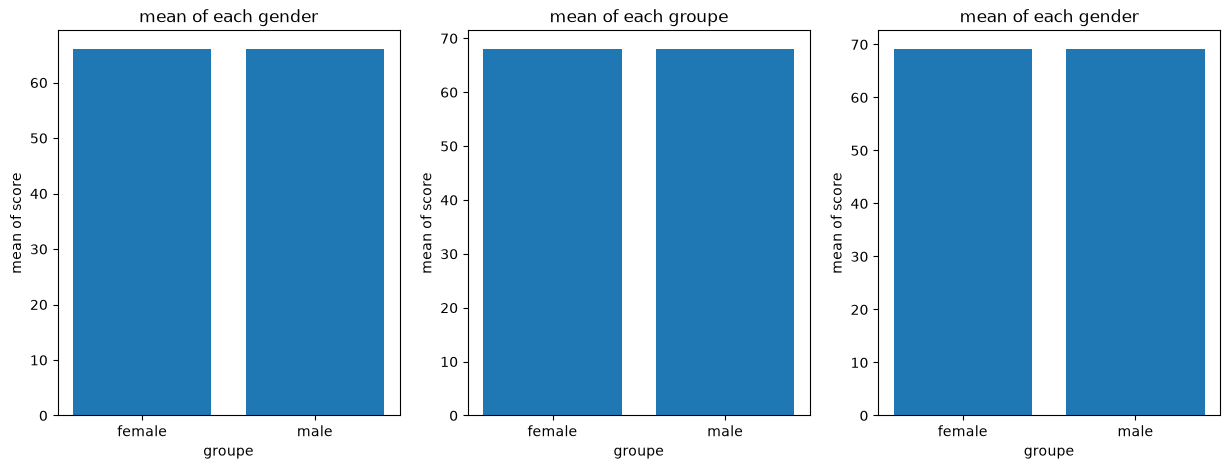

In [60]:
plt.figure(figsize=(15, 5))
plt.subplot(1,3,1)
plt.bar(df["gender"],df["math score"].mean())
plt.xlabel("groupe")
plt.ylabel("mean of score")
plt.title("mean of each gender")
plt.subplot(1,3,2)
plt.bar(df["gender"],df["writing score"].mean())
plt.xlabel("groupe")
plt.ylabel("mean of score")
plt.title("mean of each groupe")
plt.subplot(1,3,3)
plt.bar(df["gender"],df["reading score"].mean())
plt.xlabel("groupe")
plt.ylabel("mean of score")
plt.title("mean of each gender")
plt.savefig("../graphes/graphe2",dpi=300)
plt.show()

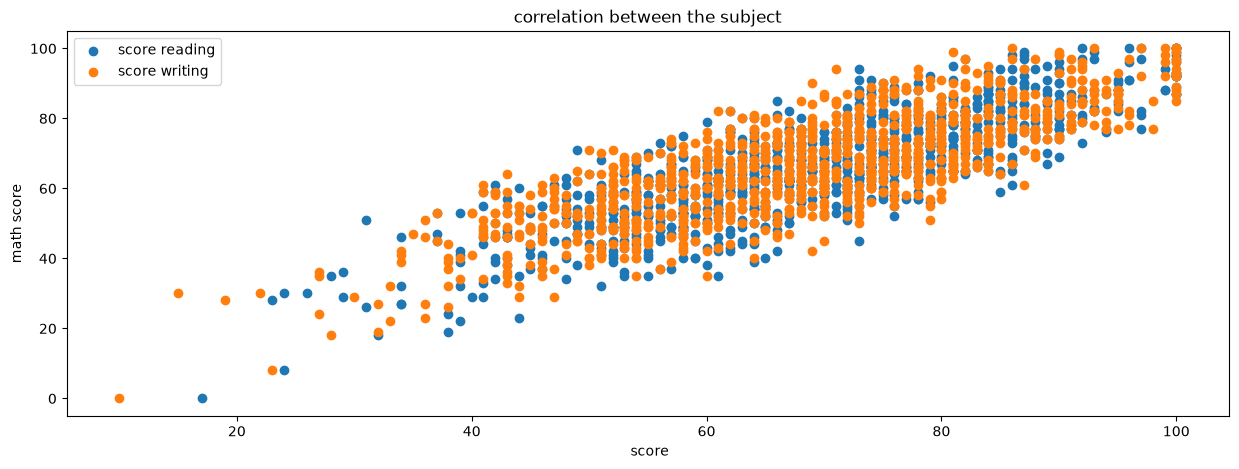

In [64]:
plt.figure(figsize=(15,5))
plt.scatter(df["reading score"],df["math score"],label="score reading")
plt.scatter(df["writing score"],df["math score"],label="score writing")
plt.legend()
plt.xlabel(" score")
plt.ylabel("math score")
plt.title("correlation between the subject")
plt.savefig("../graphes/graphe3")
plt.show()

we see that if you had highe score in the math than he have score identique of the the other subject
so its positive corr

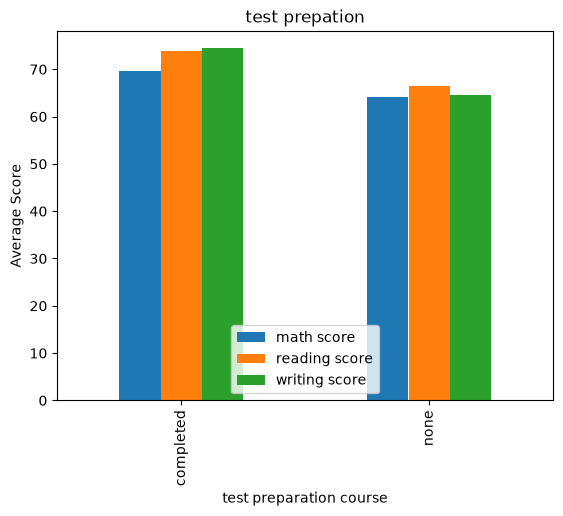

In [67]:
df.groupby("test preparation course")[
    ["math score", "reading score", "writing score"]
].mean().plot(kind="bar")
plt.title("test prepation")
plt.ylabel("Average Score")
plt.legend()
plt.savefig("../graphes/graphe4")
plt.show()

the result show that the test prepation has good impact and  growth in the avg score for eache subject,its add like (5 pt) in the math and like (10pt) in the reading and the writing

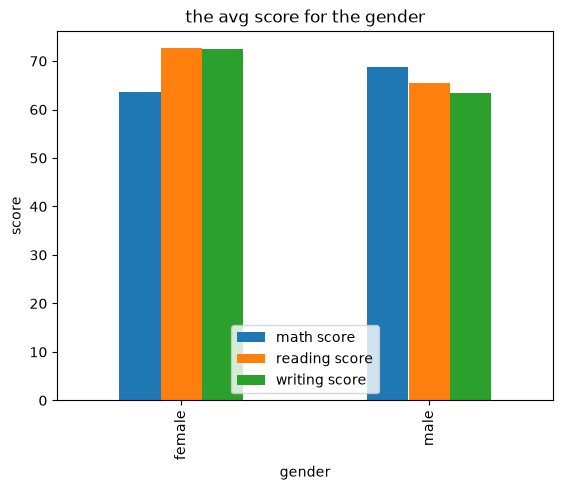

In [70]:
df.groupby("gender")[["math score", "reading score", "writing score"]].mean().plot(kind="bar")
plt.title("the avg score for the gender")
plt.xlabel("gender")
plt.ylabel("score")
plt.legend()
plt.savefig("../graphes/graphe5")
plt.show()

The results show that male students have a higher average score in mathematics than female students. However, female students have higher average scores in reading and writing. This suggests that performance differences between genders vary depending on the subject.